# MOHAMED RABBANI - DATA ANALYTICS

# OASIS INFOBYTE INTERNSHIP – TASK 1: EXPLORATORY DATA ANALYTICS (EDA)

## RETAIL SALES DATASET ANALYSIS

**Track:** Data Analytics

**Internship:** Oasis Infobyte

**Objective:** To analyze retail sales data, identify sales trends, understand customer behavior, and derive actionable business insights.

**Dataset:** Retail Sales Dataset (Kaggle, Mohammad Talib), 1000 transactions

**Tools Used:** Python, Pandas, Numpy, Matplotlib, Seaborn

### STEP 1: Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### STEP 2: Load Dataset

In [2]:
Retail_Sales = pd.read_csv("retail_sales_dataset.csv")

Retail_Sales_Backup = Retail_Sales.copy()

print("Dataset loaded successfully!")
Retail_Sales.head()

Dataset loaded successfully!


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


### STEP 3: Initial inspection

The dataset was inspected to understand its structure, column names, data types, missing values, and duplicate records. These checks help assess the dataset's quality before performing further analysis.

In [3]:
print("Dataset shape:", Retail_Sales.shape)

print("\nColumn Names:", Retail_Sales.columns.tolist())

print("\nData Types:")
print(Retail_Sales.dtypes)

print("\nMissing Values:\n")
print(Retail_Sales.isnull().sum())

print("\nDuplicate Rows:", Retail_Sales.duplicated().sum())

print("\nDataset Information:")
Retail_Sales.info()

print('Unique Customer',Retail_Sales['Customer ID'].nunique())

Dataset shape: (1000, 9)

Column Names: ['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']

Data Types:
Transaction ID      int64
Date                  str
Customer ID           str
Gender                str
Age                 int64
Product Category      str
Quantity            int64
Price per Unit      int64
Total Amount        int64
dtype: object

Missing Values:

Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

Duplicate Rows: 0

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    1000 non-null   int64
 1   Date              1000 non-null   str  
 2   Customer ID       1000 no

### Observation: Initial Inspection

- The dataset has 1000 rows and 9 columns, covering 1 January 2023 to 1 January 2024.
- There are no missing values and no duplicate rows.
- `Date` is stored as text, so it was converted to datetime format.
- All 1000 Customer IDs are unique, so repeat customers cannot be analysed.

### STEP 4: Data Preparation

In [4]:
Retail_Sales['Date'] = pd.to_datetime(Retail_Sales['Date'])
Retail_Sales['Year_Month'] = Retail_Sales['Date'].dt.to_period('M').astype(str)
Retail_Sales['Year_Quarter'] = Retail_Sales['Date'].dt.to_period('Q').astype(str)

print('Minimum Age:',Retail_Sales['Age'].min())
print('Maximum Age:',Retail_Sales['Age'].max())

age_bins = [0, 25, 35, 45, 55, 64]
age_labels = ['18-25', '26-35', '36-45', '46-55', '56-64']

Retail_Sales['Age_Group'] = pd.cut(Retail_Sales['Age'],bins=age_bins,labels=age_labels)
print("\nDate range:", Retail_Sales['Date'].min(), "to", Retail_Sales['Date'].max())

Retail_Sales.head()

Minimum Age: 18
Maximum Age: 64

Date range: 2023-01-01 00:00:00 to 2024-01-01 00:00:00


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount,Year_Month,Year_Quarter,Age_Group
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150,2023-11,2023Q4,26-35
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000,2023-02,2023Q1,26-35
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30,2023-01,2023Q1,46-55
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500,2023-05,2023Q2,36-45
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100,2023-05,2023Q2,26-35


### STEP 5: Descriptive Statistics Analysis

Descriptive statistics were used to understand the distribution of customer ages, purchase quantities, unit prices, and total transaction amounts. Mean, median, mode, and standard deviation were calculated to summarise the numerical data.

In [5]:
Numeric_Columns = ['Age', 'Quantity', 'Price per Unit', 'Total Amount']

print(Retail_Sales[Numeric_Columns].describe())

Summary_table = pd.DataFrame({
    "Mean": Retail_Sales[Numeric_Columns].mean(),
    "Median": Retail_Sales[Numeric_Columns].median(),
    "Mode": Retail_Sales[Numeric_Columns].mode().iloc[0],
    "Std Dev": Retail_Sales[Numeric_Columns].std()
})

Summary_table.round(2)

              Age     Quantity  Price per Unit  Total Amount
count  1000.00000  1000.000000     1000.000000   1000.000000
mean     41.39200     2.514000      179.890000    456.000000
std      13.68143     1.132734      189.681356    559.997632
min      18.00000     1.000000       25.000000     25.000000
25%      29.00000     1.000000       30.000000     60.000000
50%      42.00000     3.000000       50.000000    135.000000
75%      53.00000     4.000000      300.000000    900.000000
max      64.00000     4.000000      500.000000   2000.000000


,Mean,Median,Mode,Std Dev
Age,41.39,42.0,43.0,13.68
Quantity,2.51,3.0,4.0,1.13
Price per Unit,179.89,50.0,50.0,189.68
Total Amount,456.00,135.0,50.0,560.00


### Observation: Descriptive Statistics

- **Age:** The mean (41.39), median (42), and mode (43) are close to each other. The observed ages range from 18 to 64, but this does not necessarily mean that ages are evenly distributed.
- **Quantity:** The mean is 2.51, the median is 3, and the mode is 4. Transactions generally involve a small number of items.
- **Price per Unit:** The mean (179.89) is higher than the median and mode (50), suggesting that higher-priced items increase the average unit price.
- **Total Amount:** The mean (456) is higher than the median (135), suggesting a right-skewed distribution. The standard deviation (560) indicates substantial variation in transaction amounts.

### STEP 6: Time Series Analysis

Monthly and quarterly sales were analysed to identify changes in sales performance over time. Grouping sales by year and month or year and quarter helps reveal periods with relatively high or low revenue.

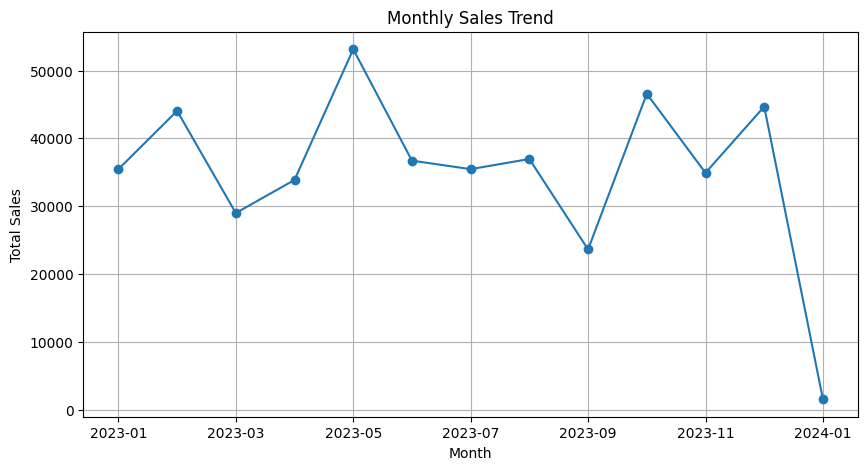

Year_Month
2023-01    35450
2023-02    44060
2023-03    28990
2023-04    33870
2023-05    53150
2023-06    36715
2023-07    35465
2023-08    36960
2023-09    23620
2023-10    46580
2023-11    34920
2023-12    44690
2024-01     1530
Name: Total Amount, dtype: int64


In [6]:
Monthly_sales = Retail_Sales.groupby('Year_Month')['Total Amount'].sum()

Monthly_sales.plot(marker='o', figsize=(10, 5))
plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.grid(True)
plt.show()

print(Monthly_sales)

### Observation: Monthly Sales Trend

- Sales were highest in May 2023 (53,150) and lowest in September 2023 (23,620).
- Sales go up and down every month with no steady trend.
- January 2024 looks very low only because the data has just one day of that month.

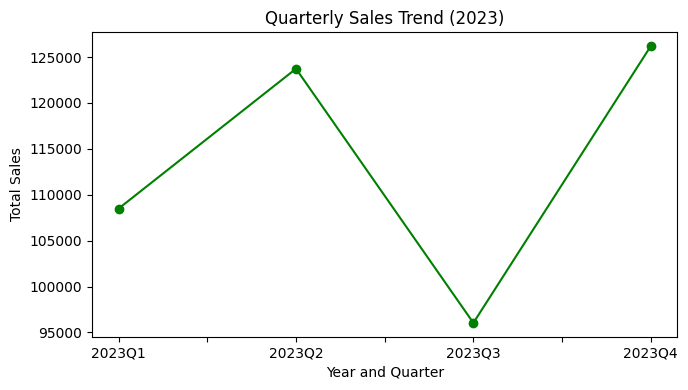

Year_Quarter
2023Q1    108500
2023Q2    123735
2023Q3     96045
2023Q4    126190
Name: Total Amount, dtype: int64


In [7]:
Quarterly_sales = Retail_Sales[Retail_Sales['Date'].dt.year == 2023].groupby('Year_Quarter')['Total Amount'].sum()

Quarterly_sales.plot(marker='o', color='green', figsize=(7, 4))
plt.title('Quarterly Sales Trend (2023)')
plt.xlabel('Year and Quarter')
plt.ylabel('Total Sales')
plt.tight_layout()
plt.show()

print(Quarterly_sales)

### Observation: Quarterly Sales Trend

- Q4 had the highest sales (around 126,190) and Q3 had the lowest (around 96,045).
- Sales dropped in Q3 and recovered strongly in Q4.

**Key Insight:** Monthly sales peaked in May 2023, while quarterly sales were strongest in Q4 2023. Businesses can prepare inventory and promotions ahead of these stronger sales periods and investigate the reasons for lower sales in September and Q3.

### STEP 7: Customer Demographics

Customer transactions were analysed by age group and gender to understand purchasing patterns across demographic categories. The visualisations help compare transaction counts and spending contributions between groups.

#### 7.1 Age Group Analysis

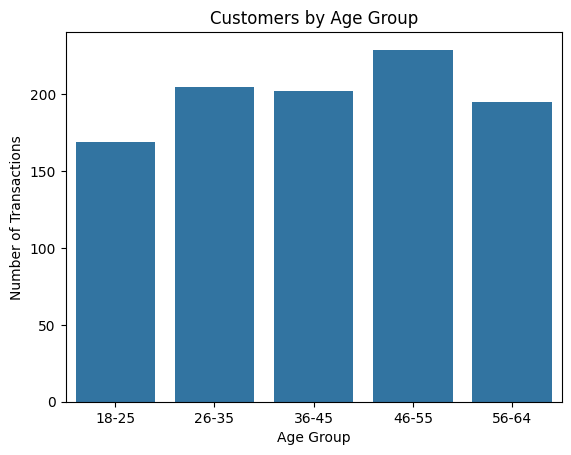

In [8]:
sns.countplot(x='Age_Group', data=Retail_Sales)
plt.title('Customers by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Number of Transactions')
plt.show()

### Observation: Age Group

- The 46-55 age group had the highest number of transactions.
- This age group also recorded the highest total spending.
- The 56-64 age group had the lowest total spending.

#### 7.2 Gender-wise Customer Analysis

This analysis compares the number of transactions made by customers of different genders.

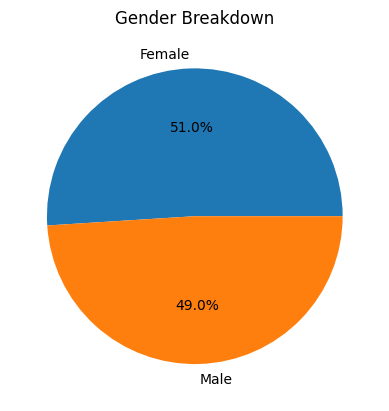

In [9]:
Retail_Sales['Gender'].value_counts().plot(kind='pie', autopct='%1.1f%%')
plt.title('Gender Breakdown')
plt.ylabel('')
plt.show()

### Observation: Gender

- Female customers are 51% and Male customers are 49%, so the split is almost equal.
- Female customers spend slightly more overall (232,840 compared to 223,160 for Male customers).

### STEP 8: Product Analysis

Revenue and quantity sold were compared across product categories to identify the categories contributing most to sales. Analysing both measures provides a broader understanding of category performance.

#### 8.1 Revenue by Category

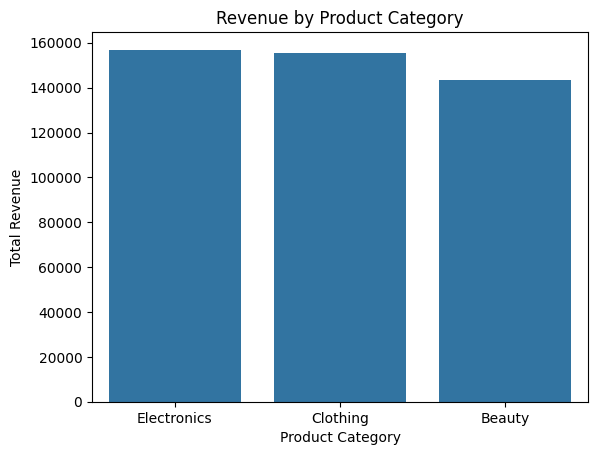

In [10]:
Category_revenue = Retail_Sales.groupby('Product Category')['Total Amount'].sum().sort_values(ascending=False)

sns.barplot(x=Category_revenue.index, y=Category_revenue.values)
plt.title('Revenue by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Revenue')
plt.show()

### Observation: Revenue by Category

- Electronics has the highest revenue (156,905) and Beauty the lowest (143,515).
- All three categories are close, so no single category dominates.
- The dataset has no product names, so the analysis is done by category instead of top 10 products.

#### 8.2 Best-Selling Category (by Quantity)

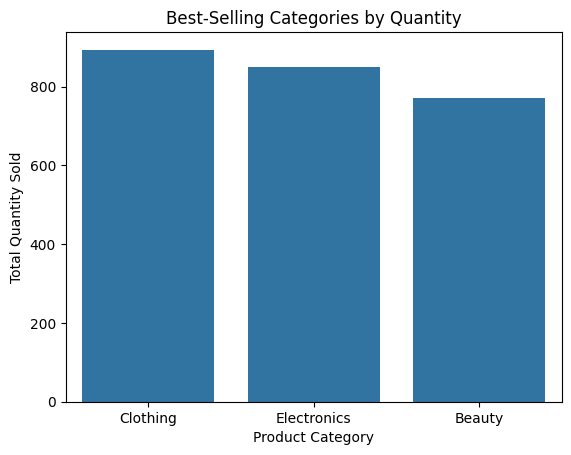

In [11]:
Category_quantity = Retail_Sales.groupby('Product Category')['Quantity'].sum().sort_values(ascending=False)

sns.barplot(x=Category_quantity.index, y=Category_quantity.values)
plt.title('Best-Selling Categories by Quantity')
plt.xlabel('Product Category')
plt.ylabel('Total Quantity Sold')
plt.show()

In [12]:
print("--- Revenue by Category ---")
print(Category_revenue)
print("\n--- Quantity Sold by Category ---")
print(Category_quantity)
print("\n--- Average Price per Unit by Category ---")
print(Retail_Sales.groupby('Product Category')['Price per Unit'].mean().round(2))

--- Revenue by Category ---
Product Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64

--- Quantity Sold by Category ---
Product Category
Clothing       894
Electronics    849
Beauty         771
Name: Quantity, dtype: int64

--- Average Price per Unit by Category ---
Product Category
Beauty         184.06
Clothing       174.29
Electronics    181.90
Name: Price per Unit, dtype: float64


### Observation: Quantity and Price by Category

- Clothing had the highest quantity sold, with 894 units.
- Electronics sold 849 units, while Beauty sold 771 units.
- Beauty had the highest average price per unit at 184.06.
- Clothing had the lowest average price per unit at 174.29.

### STEP 9: Correlation Analysis

#### 9.1 Correlation Heatmap

A correlation heatmap shows the relationships between numerical variables. Correlation values range from -1 to +1 and help identify positive and negative relationships between variables.

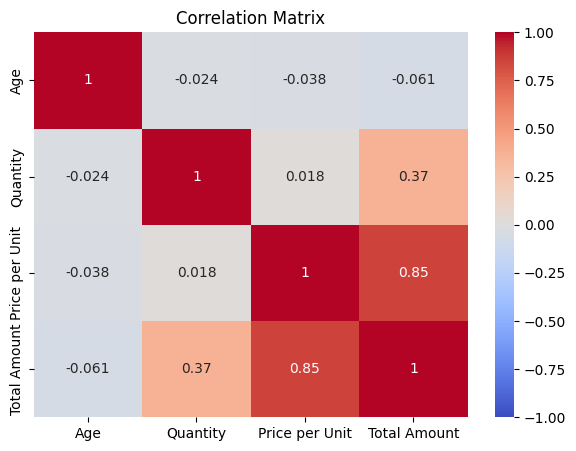

In [13]:
plt.figure(figsize=(7, 5))
sns.heatmap(Retail_Sales[Numeric_Columns].corr(), annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix')
plt.show()

### Observation: Correlation Matrix

- **Total Amount vs Price per Unit:** correlation 0.85, a strong positive relationship.
- **Total Amount vs Quantity:** correlation 0.37, a weak to moderate positive relationship.
- **Age** has a very weak relationship with Total Amount (-0.06), Quantity (-0.02) and Price per Unit (-0.04).
- Quantity and Price per Unit are almost no linear relationship to each other (0.02). Total Amount is calculated as Quantity × Price per Unit, so it is naturally linked to both.

### STEP 10: Extra Visualisation (Customer Spending)

#### 10.1 Age Group vs Product Category Spending

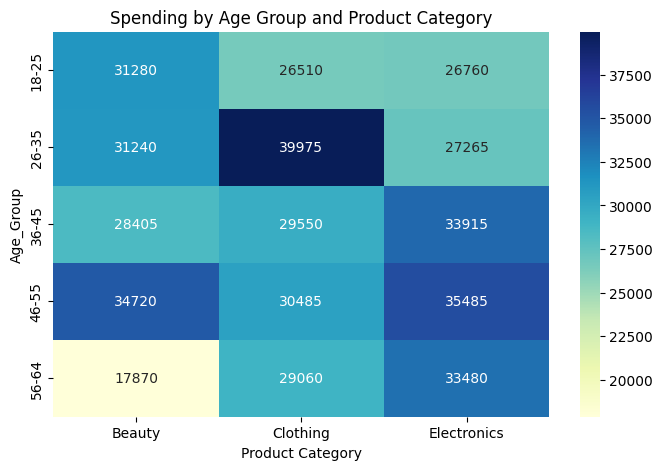

In [14]:
Age_category_spending = Retail_Sales.pivot_table(values='Total Amount',
                                                index='Age_Group',
                                                columns='Product Category',
                                                aggfunc='sum',
                                                observed=True)

plt.figure(figsize=(8, 5))
sns.heatmap(Age_category_spending, annot=True, fmt='.0f', cmap='YlGnBu')
plt.title('Spending by Age Group and Product Category')
plt.show()

#### 10.2 Gender vs Product Category Spending

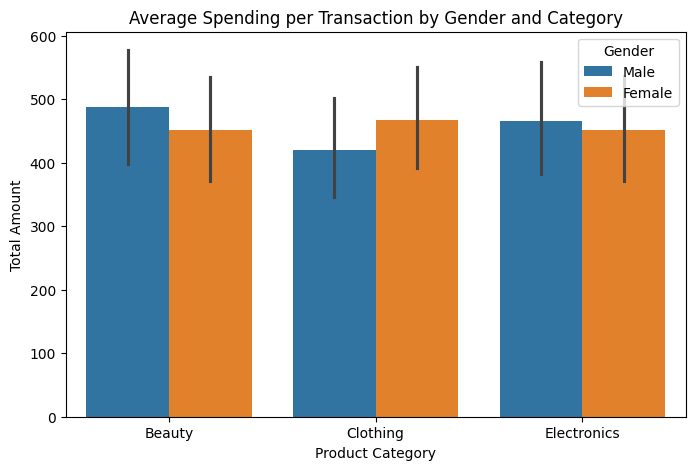

In [15]:
plt.figure(figsize=(8, 5))
sns.barplot(x='Product Category', y='Total Amount', hue='Gender', data=Retail_Sales)
plt.title('Average Spending per Transaction by Gender and Category')
plt.show()

### Observation: Customer Spending Analysis (Extra Visualisation)

- The 26-35 age group recorded the highest spending on Clothing (39,975).
- The 56-64 age group recorded the lowest spending on Beauty (17,870).
- Male and female spending per transaction is similar in every category, with only small differences.

### STEP 11: Conclusion and Recommendations

In [16]:
Monthly_sales_2023 = Monthly_sales[Monthly_sales.index.str.startswith('2023')]

print("Top category by revenue:", Category_revenue.idxmax(), Category_revenue.max())
print("Lowest category by revenue:", Category_revenue.idxmin(), Category_revenue.min())
print("Peak month (2023):", Monthly_sales_2023.idxmax(), Monthly_sales_2023.max())
print("Lowest month (2023):", Monthly_sales_2023.idxmin(), Monthly_sales_2023.min())
print("Top age group:", Retail_Sales.groupby('Age_Group', observed=True)['Total Amount'].sum().idxmax())
print("Top gender:", Retail_Sales.groupby('Gender')['Total Amount'].sum().idxmax())
print("\nTotal spending by gender:")
print(Retail_Sales.groupby('Gender')['Total Amount'].sum())

Top category by revenue: Electronics 156905
Lowest category by revenue: Beauty 143515
Peak month (2023): 2023-05 53150
Lowest month (2023): 2023-09 23620
Top age group: 46-55
Top gender: Female

Total spending by gender:
Gender
Female    232840
Male      223160
Name: Total Amount, dtype: int64


## Conclusion

### Key Findings
- Electronics earned the highest revenue (156,905) and Beauty the lowest (143,515), but all three categories are close.
- Sales peaked in May 2023 and were lowest in September 2023.
- The 46-55 age group and female customers spend the most.
- Price per Unit has a strong positive correlation with Total Amount (0.85) in this dataset.
- A few high-value purchases pull the average spending above the median.

### Recommendations
1. **Promote Electronics and Clothing.** They bring the highest revenue (156,905 and 155,580), so bundle offers can increase sales further.
2. **Plan stock and offers around peak and slow periods.** Sales were 53,150 in May but only 23,620 in September, so run discounts in slow months.
3. **Target age groups by category.** Promote Clothing to the 26-35 group (39,975) and run Beauty offers for the 56-64 group, whose Beauty spending is lowest (17,870).
4. **Start a loyalty programme.** All 1000 transactions are from unique customers, so rewards can help turn one-time buyers into repeat customers.